# DANDI:001888 NWB Tutorial: EEG recordings from a Grin2b+/- rat model of GRIN2B neurodevelopmental disorder: absence seizures and sleep-wake abnormalities

This notebook shows how to read and plot the Gonzalez-Sulser lab dataset ([Hristova et al. 2025](https://doi.org/10.1111/epi.18606)) on [DANDI:001888](https://dandiarchive.org/dandiset/001888). Each NWB file holds one rat: the full raw EEG and EMG recording (72 to 96 h), the two 24-h baseline windows the lab analyzed, and the lab's processed streams of those windows. It covers:

1. Loading or streaming the NWB file and inspecting top-level metadata
2. Reading raw EEG/EMG acquisition data
3. Full-recording EEG spectrogram
4. Reading sleep-state epochs
5. Sleep states by hour
6. HED tags and ontology terms of the sleep states
7. Reading per-sleep-state power spectra
8. Reading seizure event intervals
9. EEG/EMG around a seizure event
10. Reading per-epoch spike-wave discharge (SWD) flags
11. Accessing external ontology resources (HERD)

The notebook can stream a file from DANDI, with no download, or read a file on disk. Everything after the loading step works the same for both.

## Setup

```bash
pip install dandi pynwb ndx-hed remfile h5py matplotlib pandas
```

PyNWB reads the HED annotations without `ndx-hed`; the notebook imports it to validate the tags (section 6).

In [1]:
# Core data manipulation and analysis
from pathlib import Path

import h5py

# HED annotations (section 6); imported before reading a file so that PyNWB uses ndx-hed's types
import ndx_hed  # noqa: F401

# Visualization
import matplotlib.pyplot as plt
import numpy as np
import remfile
from dandi.dandiapi import DandiAPIClient

# NWB and DANDI access
from pynwb import NWBHDF5IO

# Configure matplotlib
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 10

## Data Access Functions

### Stream a session directly from DANDI

DANDI assets can be read directly over HTTP with [`remfile`](https://github.com/flatironinstitute/remfile),
without downloading the file to disk.

We'll stream one session from **[DANDI:001888](https://dandiarchive.org/dandiset/001888)**.
Change `subject_id` and `session_id` for another subject; `dandiset.get_assets()` lists them all.

In [2]:
def load_nwb_from_dandi(dandiset_id, subject_id, session_id, modality):
    """
    Load NWB file from DANDI Archive via streaming.
    """
    pattern = f"sub-{subject_id}/sub-{subject_id}_ses-{session_id}_{modality}*.nwb"

    with DandiAPIClient() as client:
        assets = client.get_dandiset(dandiset_id, "draft").get_assets_by_glob(
            pattern=pattern, order="path"
        )

        s3_urls = []
        for asset in assets:
            s3_url = asset.get_content_url(follow_redirects=1, strip_query=False)
            s3_urls.append(s3_url)

        if len(s3_urls) != 1:
            raise ValueError(
                f"Expected 1 file, found {len(s3_urls)} for pattern {pattern}"
            )

        s3_url = s3_urls[0]

    file = remfile.File(s3_url)
    h5_file = h5py.File(file, "r")
    io = NWBHDF5IO(file=h5_file, load_namespaces=True)
    nwbfile = io.read()

    return nwbfile, io

### Read a local NWB file

If the file is on disk, for example downloaded with `dandi download`, reading it is a standard `NWBHDF5IO` call.
The files are organized as `sub-<subject>/sub-<subject>_ses-<session>_ecephys.nwb`.

In [3]:
def load_nwb_local(directory_path, subject_id, session_id, modality):
    """
    Load NWB file from a local dandiset folder (sub-<subject>/sub-<subject>_ses-<session>_<modality>.nwb).
    """
    nwbfile_path = Path(directory_path) / f"sub-{subject_id}" / f"sub-{subject_id}_ses-{session_id}_{modality}.nwb"

    if not nwbfile_path.exists():
        raise FileNotFoundError(f"NWB file not found: {nwbfile_path}")

    io = NWBHDF5IO(path=nwbfile_path, load_namespaces=True)
    nwbfile = io.read()

    return nwbfile, io

## 1. Load and inspect top-level metadata

### Choose which source to explore

In [4]:
# Choose data source (DANDI streaming or local)
USE_DANDI = True  # Set to False to read a local file
dandiset_id = "001888"
subject_id = "GRIN2B-129"
session_id = "2021-03-26"
modality = "ecephys"
if USE_DANDI:
    nwbfile, io = load_nwb_from_dandi(dandiset_id, subject_id, session_id, modality)
else:
    local_directory = "<path to the dandiset folder>"  # the folder that holds the sub-* folders
    nwbfile, io = load_nwb_local(local_directory, subject_id, session_id, modality)

In [5]:
print("=== SESSION INFORMATION ===")
print(f"Session description: {nwbfile.session_description}")
print(f"Session start time: {nwbfile.session_start_time}")
print(f"Experiment description: {nwbfile.experiment_description}")

=== SESSION INFORMATION ===
Session description: Chronic wireless EEG/EMG recording, subject GRIN2B_129, full raw recording with BL1 and BL2 24-h baseline window(s) marked in the NWB epochs table. 
Session start time: 2021-03-26 10:56:00+00:00
Experiment description: Chronic wireless EEG and EMG recordings from freely behaving Long-Evans rats carrying a heterozygous knockout of Grin2b (Grin2b+/-), the gene encoding the GluN2B subunit of N-methyl-D-aspartate receptors (NMDARs). Grin2b+/- rats display spontaneous spike-and-wave discharges (SWDs, the electrographic correlate of absence seizures) at higher incidence and duration than wild-type littermates, alongside reduced REM sleep and altered NREM/wake distributions. Recordings were acquired over 72-96 h using the TaiNi wireless multichannel recording system (Tainitec, UK) with 14-channel skull-surface EEG electrode grids and bilateral neck EMG electrodes, at 250.4 Hz. Two consecutive 24-h baseline windows (BL1, BL2) were extracted per 

In [6]:
print(f"Session ID:          {nwbfile.session_id}")
print(f"Session start time:  {nwbfile.session_start_time}")
print(f"Institution:         {nwbfile.institution}")
print(f"Lab:                 {nwbfile.lab}")
print(f"Subject ID:          {nwbfile.subject.subject_id}")
print(f"Subject species:     {nwbfile.subject.species}")
print(f"Subject genotype:    {nwbfile.subject.genotype}")
print(f"Subject sex:         {nwbfile.subject.sex}")
print()
print("Acquisition keys:", list(nwbfile.acquisition.keys()))
print("Processing modules:", list(nwbfile.processing.keys()))

epochs_df = nwbfile.epochs.to_dataframe()
print()
print(
    "Baseline windows 1 and 2 are marked in the NWB epochs table (seconds relative to session_start_time)"
)
epochs_df[:]
bl1_start_time = epochs_df["start_time"][0]
bl2_start_time = epochs_df["start_time"][1]

Session ID:          2021-03-26
Session start time:  2021-03-26 10:56:00+00:00
Institution:         University of Edinburgh
Lab:                 Gonzalez-Sulser Lab
Subject ID:          GRIN2B-129
Subject species:     Rattus norvegicus
Subject genotype:    LE-Grin2bem1Mcwi
Subject sex:         M

Acquisition keys: ['EEGElectricalSeries', 'EMGElectricalSeries']
Processing modules: ['behavior', 'ecephys']

Baseline windows 1 and 2 are marked in the NWB epochs table (seconds relative to session_start_time)


In [7]:
nwbfile

root pynwb.file.NWBFile at 0x1222734765072
Fields:
  acquisition: {
    EEGElectricalSeries <class 'pynwb.ecephys.ElectricalSeries'>,
    EMGElectricalSeries <class 'pynwb.ecephys.ElectricalSeries'>
  }
  device_models: {
    TainiTec wireless EEG and EMG transmitter <class 'pynwb.device.DeviceModel'>
  }
  devices: {
    TainiTecWirelessEEG <class 'pynwb.device.Device'>
  }
  electrode_groups: {
    EEGArray <class 'pynwb.ecephys.ElectrodeGroup'>,
    EMGArray <class 'pynwb.ecephys.ElectrodeGroup'>
  }
  electrodes: electrodes <class 'pynwb.ecephys.ElectrodesTable'>
  epochs: epochs <class 'pynwb.epoch.TimeIntervals'>
  experiment_description: Chronic wireless EEG and EMG recordings from freely behaving Long-Evans rats carrying a heterozygous knockout of Grin2b (Grin2b+/-), the gene encoding the GluN2B subunit of N-methyl-D-aspartate receptors (NMDARs). Grin2b+/- rats display spontaneous spike-and-wave discharges (SWDs, the electrographic correlate of absence seizures) at higher incidence and duration than wild-type littermates, alongside reduced REM sleep and altered NREM/wake distributions. Recordings were acquired over 72-96 h using the TaiNi wireless multichannel recording system (Tainitec, UK) with 14-channel skull-surface EEG electrode grids and bilateral neck EMG electrodes, at 250.4 Hz. Two consecutive 24-h baseline windows (BL1, BL2) were extracted per animal. Automated pipelines classified sleep states (Wake, NREM, REM) in 5-s epochs and detected SWD seizure events. Data contribute to the SFARI Autism Rat Models Consortium (ARC).

  experimenter: ['Hristova, Katerina' 'Fasol, Melissa C. M.' 'McLaughlin, Niamh'
 'Nawaz, Mohammad Sarfaraz' 'Taskiran, Mehmet' 'Buller-Peralta, Ingrid'
 'Harris, Anjanette P.' 'Sutherland, Andrew' 'Bassi, Alejandro'
 'Ocampo-Garces, Adrian' 'Escudero, Javier' 'Kind, Peter C.'
 'Gonzalez-Sulser, Alfredo']
  external_resources: external_resources hdmf.common.resources.HERD at 0x1222754366416
  27 key(s), 24 entity(ies), 8 object(s), 1 file(s)
                          file_object_id  objects_idx  \
0   40afe00e-d102-4f01-b79a-bf557f74e835            0   
1   40afe00e-d102-4f01-b79a-bf557f74e835            0   
2   40afe00e-d102-4f01-b79a-bf557f74e835            0   
3   40afe00e-d102-4f01-b79a-bf557f74e835            1   
4   40afe00e-d102-4f01-b79a-bf557f74e835            2   
5   40afe00e-d102-4f01-b79a-bf557f74e835            3   
6   40afe00e-d102-4f01-b79a-bf557f74e835            3   
7   40afe00e-d102-4f01-b79a-bf557f74e835            3   
8   40afe00e-d102-4f01-b79a-bf557f74e835            3   
9   40afe00e-d102-4f01-b79a-bf557f74e835            3   
10  40afe00e-d102-4f01-b79a-bf557f74e835            3   
11  40afe00e-d102-4f01-b79a-bf557f74e835            3   
12  40afe00e-d102-4f01-b79a-bf557f74e835            3   
13  40afe00e-d102-4f01-b79a-bf557f74e835            4   
14  40afe00e-d102-4f01-b79a-bf557f74e835            5   
15  40afe00e-d102-4f01-b79a-bf557f74e835            6   
16  40afe00e-d102-4f01-b79a-bf557f74e835            6   
17  40afe00e-d102-4f01-b79a-bf557f74e835            6   
18  40afe00e-d102-4f01-b79a-bf557f74e835            6   
19  40afe00e-d102-4f01-b79a-bf557f74e835            6   
20  40afe00e-d102-4f01-b79a-bf557f74e835            6   
21  40afe00e-d102-4f01-b79a-bf557f74e835            6   
22  40afe00e-d102-4f01-b79a-bf557f74e835            6   
23  40afe00e-d102-4f01-b79a-bf557f74e835            6   
24  40afe00e-d102-4f01-b79a-bf557f74e835            6   
25  40afe00e-d102-4f01-b79a-bf557f74e835            6   
26  40afe00e-d102-4f01-b79a-bf557f74e835            7   

                               object_id  files_idx     object_type  \
0   cfffd8ab-0281-4c3f-8b9c-9e5664cfedff          0      VectorData   
1   cfffd8ab-0281-4c3f-8b9c-9e5664cfedff          0      VectorData   
2   cfffd8ab-0281-4c3f-8b9c-9e5664cfedff          0      VectorData   
3   d2b44ec3-f86a-4034-9e93-6a783d218156          0         Subject   
4   d2b44ec3-f86a-4034-9e93-6a783d

## 2. Raw EEG / EMG

The full recording (72 to 96 h) is stored as **two** `ElectricalSeries` in `acquisition`, one for EEG and one for
EMG, sharing a single electrode table but linked to distinct `ElectrodeGroup`s:

- `EEGElectricalSeries`: **14 EEG channels** over bilateral cortex (S1-Tr, M2-FrA, M2-Ant, M1-Ant, V2-ML, V1-M,
  S1-HL/FL, right and left)
- `EMGElectricalSeries`: **2 EMG channels** in the trapezius muscles, right and left

The data are the raw ADC codes; `data * conversion + offset` gives volts.

In [8]:
eeg_name = next(name for name in nwbfile.acquisition if name.startswith("EEGElectricalSeries"))
emg_name = next(name for name in nwbfile.acquisition if name.startswith("EMGElectricalSeries"))
eeg_es = nwbfile.acquisition[eeg_name]
emg_es = nwbfile.acquisition[emg_name]

for name, es in [("EEG", eeg_es), ("EMG", emg_es)]:
    print(f"--- {name} ---")
    print(f"ElectricalSeries shape:  {es.data.shape}")
    print(f"Sampling rate:           {es.rate} Hz")
    print(
        f"Starting time:           {es.starting_time:.2f} s (= session_start_time; full recording)"
    )
    print(f"Duration:                {es.data.shape[0] / es.rate / 3600:.2f} h")
    print(f"Conversion (to volts):   {es.conversion:.6e}")
    print(f"Offset (volts):          {es.offset}")
    print()

electrodes = nwbfile.electrodes.to_dataframe()
electrodes[:]

--- EEG ---
ElectricalSeries shape:  (69391534, 14)
Sampling rate:           250.4 Hz
Starting time:           0.00 s (= session_start_time; full recording)
Duration:                76.98 h
Conversion (to volts):   3.174603e-06
Offset (volts):          -0.0065

--- EMG ---
ElectricalSeries shape:  (69391534, 2)
Sampling rate:           250.4 Hz
Starting time:           0.00 s (= session_start_time; full recording)
Duration:                76.98 h
Conversion (to volts):   3.174603e-06
Offset (volts):          -0.0065



,location,group,group_name,channel_name,filtering,hemisphere,x,z
id,,,,,,,,
0,"primary somatosensory cortex, trunk region (S1...",EEGArray pynwb.ecephys.ElectrodeGroup at 0x122...,EEGArray,S1_Tr_R,none,R,3000.0,2800.0
1,"secondary motor cortex, frontal association ar...",EEGArray pynwb.ecephys.ElectrodeGroup at 0x122...,EEGArray,M2_Fra_R,none,R,-3600.0,1200.0
2,"secondary motor cortex, anterior (M2-Ant)",EEGArray pynwb.ecephys.ElectrodeGroup at 0x122...,EEGArray,M2_anterior_R,none,R,-1500.0,1200.0
3,"primary motor cortex, anterior (M1-Ant)",EEGArray pynwb.ecephys.ElectrodeGroup at 0x122...,EEGArray,M1_anterior_R,none,R,-1500.0,2800.0
4,"secondary visual cortex, mediolateral area (V2...",EEGArray pynwb.ecephys.ElectrodeGroup at 0x122...,EEGArray,V2_ML_R,none,R,5000.0,3000.0
5,"primary visual cortex, monocular area (V1-M)",EEGArray pynwb.ecephys.ElectrodeGroup at 0x122...,EEGArray,V1_M_R,none,R,7000.0,3000.0
6,"primary somatosensory cortex, hindlimb and for...",EEGArray pynwb.ecephys.ElectrodeGroup at 0x122...,EEGArray,S1Hl_S1Fl_R,none,R,1000.0,2800.0
7,"primary visual cortex, monocular area (V1-M)",EEGArray pynwb.ecephys.ElectrodeGroup at 0x122...,EEGArray,V1_M_L,none,L,7000.0,-3000.0
8,"secondary visual cortex, mediolateral area (V2...",EEGArray pynwb.ecephys.ElectrodeGroup at 0x122...,EEGArray,V2_ML_L,none,L,5000.0,-3000.0


### Electrode layout on the skull

The electrode table gives, for each channel, its area (`location`, the full name with the paper's abbreviation), the
lab's channel name and hemisphere (`channel_name`, `hemisphere`), and its stereotaxic position from bregma in microns
in the `x` and `z` columns, with the NWB axes: `x` positive posterior, `z` positive right. The depth (`y`) of
skull-surface electrodes is not defined, so there is no `y` column; the EMG rows have no position. The schematic below
plots the 14 EEG electrodes on a simplified rat skull outline.

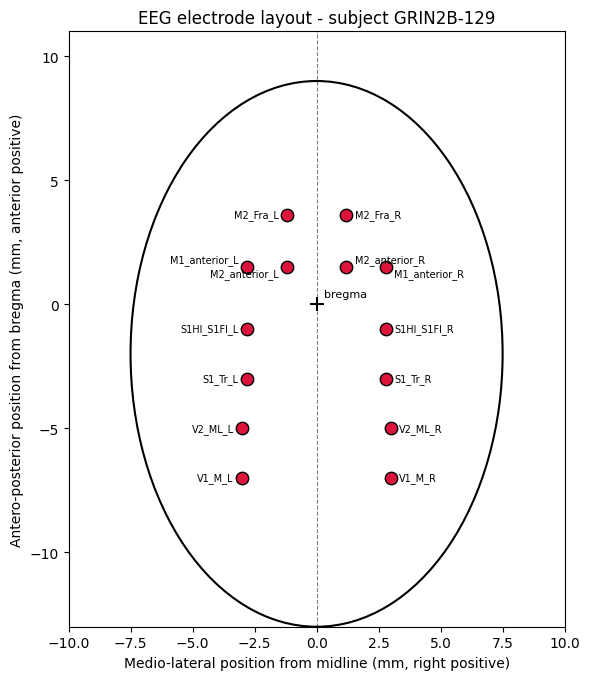

In [9]:
from matplotlib.patches import Ellipse

# Only the 14 EEG electrodes have stereotaxic coordinates (EMG rows are NaN)
eeg_electrodes = electrodes.dropna(subset=["x", "z"])

# AP (anterior positive) = -x, ML (right positive) = z, converted from microns to mm
ap = -eeg_electrodes["x"].to_numpy() / 1000
ml = eeg_electrodes["z"].to_numpy() / 1000
names = eeg_electrodes["channel_name"].to_numpy()

fig, ax = plt.subplots(figsize=(6, 8))

# Simplified rat skull outline (bregma at the origin)
skull = Ellipse(
    (0, -2), width=15, height=22, facecolor="none", edgecolor="black", lw=1.5
)
ax.add_patch(skull)
ax.axvline(0, color="gray", lw=0.8, ls="--", zorder=0)  # sagittal suture
ax.plot(0, 0, "+", color="black", ms=10, mew=1.5)  # bregma
ax.annotate("bregma", (0, 0), xytext=(0.3, 0.3), fontsize=8)

ax.scatter(ml, ap, s=80, c="crimson", edgecolor="black", zorder=3)

# Stagger labels vertically among electrodes that share (nearly) the same AP
# coordinate, so closely spaced markers (e.g. M1_anterior/M2_anterior) don't collide
order = np.argsort(ap)
dy_by_point = np.zeros(len(ap))
for group_start in range(len(order)):
    i = order[group_start]
    same_ap = [j for j in order if abs(ap[j] - ap[i]) < 0.5 and np.sign(ml[j]) == np.sign(ml[i])]
    rank = same_ap.index(i)
    dy_by_point[i] = (rank - (len(same_ap) - 1) / 2) * 10

for x, y, name, dy in zip(ml, ap, names, dy_by_point):
    dx = 6 if x >= 0 else -6
    ha = "left" if x >= 0 else "right"
    ax.annotate(
        name,
        (x, y),
        textcoords="offset points",
        xytext=(dx, dy),
        ha=ha,
        va="center",
        fontsize=7,
    )

ax.set_xlabel("Medio-lateral position from midline (mm, right positive)")
ax.set_ylabel("Antero-posterior position from bregma (mm, anterior positive)")
ax.set_title(f"EEG electrode layout - subject {nwbfile.subject.subject_id}")
ax.set_aspect("equal")
ax.set_xlim(-10, 10)
ax.set_ylim(-13, 11)
plt.tight_layout()
plt.show()

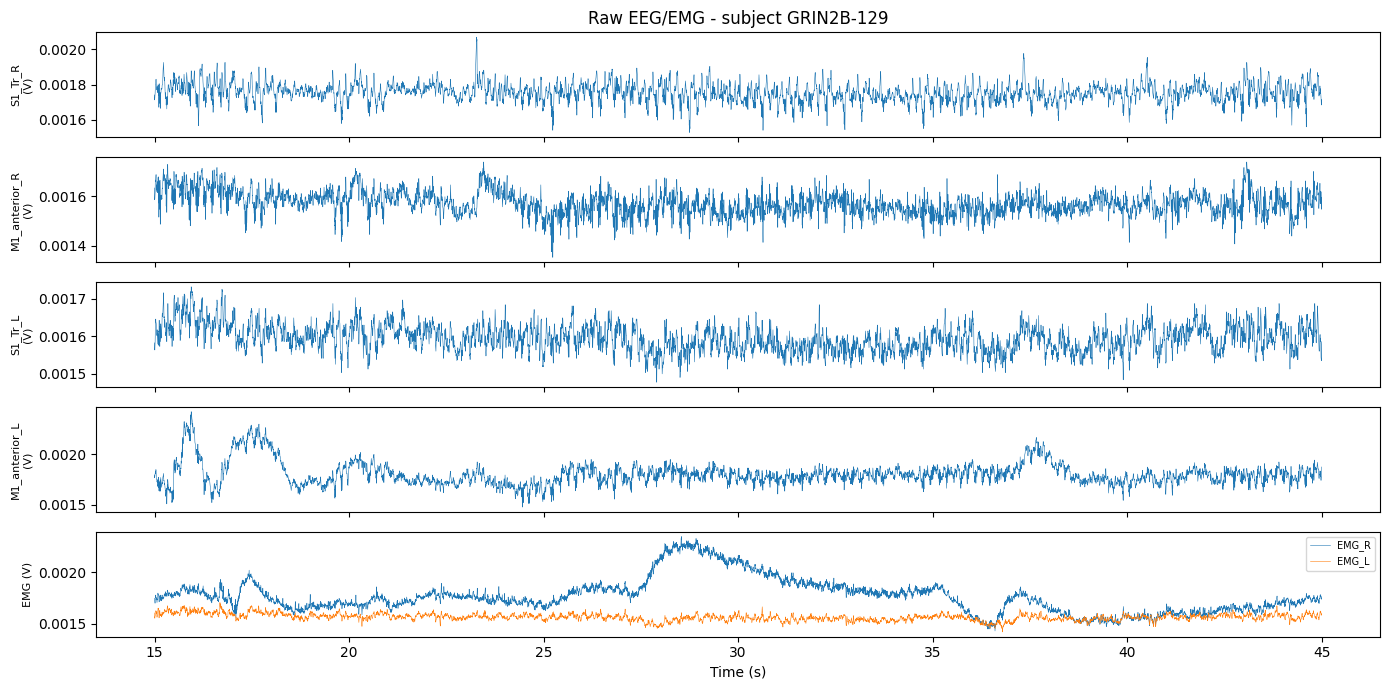

In [10]:
fs = eeg_es.rate
window_start_s = 15
window_duration_s = 30
window_end_s = window_start_s + window_duration_s

i_start = int(window_start_s * fs)
i_end = int(window_end_s * fs)

# Convert the raw ADC codes to volts (data * conversion + offset). The full recording is indexed directly
eeg_slice = eeg_es.data[i_start:i_end, :] * eeg_es.conversion + eeg_es.offset  # lazy HDF5 read
emg_slice = emg_es.data[i_start:i_end, :] * emg_es.conversion + emg_es.offset  # lazy HDF5 read

t = eeg_es.get_timestamps()[i_start:i_end]

# EEG channels: indices within EEGElectricalSeries (rows of its electrodes, in electrode-table order)
eeg_idx = {"S1_Tr_R": 0, "M1_anterior_R": 3, "S1_Tr_L": 13, "M1_anterior_L": 10}
# EMG channels: indices within EMGElectricalSeries (2 channels)
emg_idx = {"EMG_R": 0, "EMG_L": 1}

fig, axes = plt.subplots(len(eeg_idx) + 1, 1, figsize=(14, 7), sharex=True)

for ax, (label, idx) in zip(axes[:-1], eeg_idx.items()):
    ax.plot(t, eeg_slice[:, idx], lw=0.4)
    ax.set_ylabel(f"{label}\n(V)", fontsize=8)

ax_emg = axes[-1]
for label, idx in emg_idx.items():
    ax_emg.plot(t, emg_slice[:, idx], lw=0.4, label=label)
ax_emg.set_ylabel("EMG (V)", fontsize=8)
ax_emg.legend(fontsize=7, loc="upper right")
ax_emg.set_xlabel(f"Time (s)")

axes[0].set_title(f"Raw EEG/EMG - subject {nwbfile.subject.subject_id}")
plt.tight_layout()
plt.show()

## 3. EEG spectrogram

Reproduces the lab's per-epoch spectrogram plot (`spec_129_BL2.png`): raw EEG power is
computed in the same 5-s epochs as the sleep scoring, then split into fixed-duration
panels stacked top-to-bottom to cover the full recording.

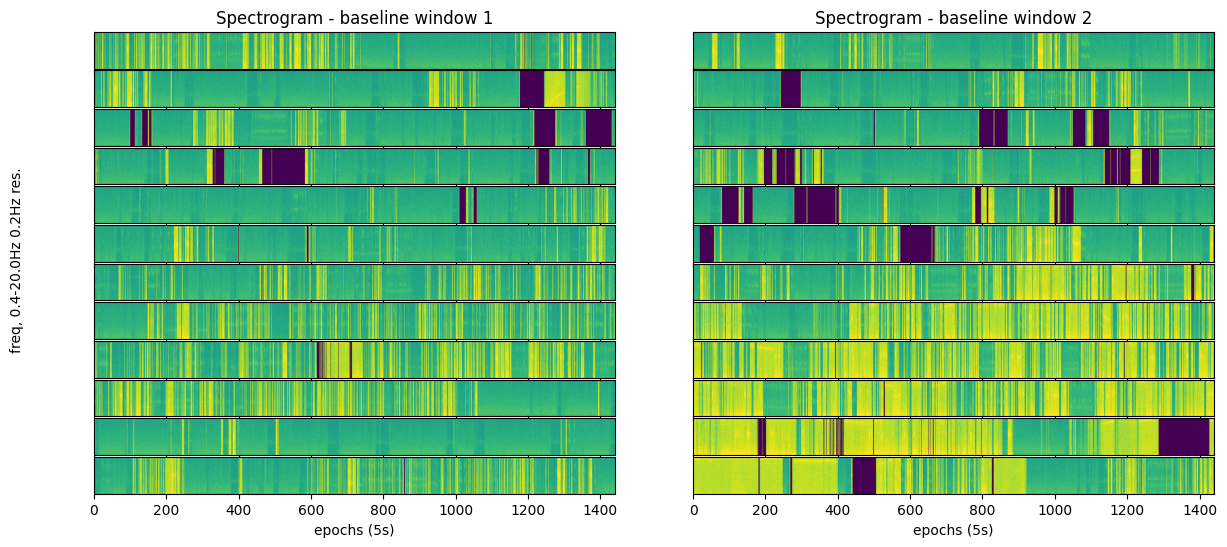

In [11]:
# ── Spectrogram parameters ────────────────────────────────────────────────────
channel_idx = 0  # EEG channel to use (index into eeg_es channels)
freq_min, freq_max = 0.4, 20.0  # Hz - matches the lab's plotting band
panel_duration_h = 2.0  # hours of recording per stacked panel
# ──────────────────────────────────────────────────────────────────────────────

fs = eeg_es.rate
epoch_len_s = 5.0  # same epoch length as the sleep scoring (Section 4)
n_per_epoch = int(round(epoch_len_s * fs))

baseline_windows = [
    ("baseline window 1", bl1_start_time, epochs_df["stop_time"][0]),
    ("baseline window 2", bl2_start_time, epochs_df["stop_time"][1]),
]

freqs = np.fft.rfftfreq(n_per_epoch, d=1 / fs)
freq_mask = (freqs >= freq_min) & (freqs <= freq_max)
freqs = freqs[freq_mask]

log_powers = []
for label, start_s, stop_s in baseline_windows:
    i_start = int(start_s * fs)
    i_stop = int(stop_s * fs)
    n_epochs = (i_stop - i_start) // n_per_epoch

    eeg_channel = eeg_es.data[
        i_start : i_start + n_epochs * n_per_epoch, channel_idx
    ]* eeg_es.conversion
    epochs = eeg_channel.reshape(n_epochs, n_per_epoch)

    power = np.abs(np.fft.rfft(epochs, axis=1)) ** 2
    log_power = np.log10(power[:, freq_mask] + np.finfo(float).eps)
    log_powers.append((label, log_power))

epochs_per_panel = int(panel_duration_h * 3600 / epoch_len_s)
n_panels = max(
    int(np.ceil(log_power.shape[0] / epochs_per_panel)) for _, log_power in log_powers
)
vmin, vmax = np.percentile(
    np.concatenate([lp for _, lp in log_powers], axis=0), [1, 99]
)

fig, axes = plt.subplots(
    n_panels, 2, figsize=(14, 0.5 * n_panels), sharex=True, squeeze=False
)
for col, (label, log_power) in enumerate(log_powers):
    n_epochs = log_power.shape[0]
    for panel in range(n_panels):
        ax = axes[panel, col]
        i0 = panel * epochs_per_panel
        i1 = min(i0 + epochs_per_panel, n_epochs)
        if i0 >= n_epochs:
            ax.axis("off")
            continue
        ax.imshow(
            log_power[i0:i1].T,
            aspect="auto",
            origin="lower",
            cmap="viridis",
            vmin=vmin,
            vmax=vmax,
            extent=[0, i1 - i0, freq_min, freq_max],
        )
        ax.set_yticks([])
    axes[0, col].set_title(f"Spectrogram - {label}")
    axes[-1, col].set_xlabel("epochs (5s)")

fig.text(
    0.04,
    0.5,
    f"freq, {freq_min}-{freq_max}Hz 0.2Hz res.",
    va="center",
    rotation="vertical",
)
plt.subplots_adjust(hspace=0.05, wspace=0.15, left=0.1)
plt.show()

## 4. Sleep-state epochs

5-second scored epochs are stored in a single table, `processing/behavior/sleep_states`, spanning both baseline
windows. A `baseline_window` column (matching the tags in `nwbfile.epochs`) identifies which baseline window each
row belongs to. State codes: 0 = Wake, 1 = NREM, 2 = REM (`sleep_score`), with the label in `sleep_state`. Epochs
with spike-wave discharges keep their Wake, NREM or REM score here; they are flagged in `swd_epochs` (section 10).

In [12]:
behavior = nwbfile.processing["behavior"]
sleep_df = behavior["sleep_states"].to_dataframe()
sleep_df_bl1 = sleep_df[sleep_df["baseline_window"] == "baseline_window_1"]
sleep_df_bl2 = sleep_df[sleep_df["baseline_window"] == "baseline_window_2"]

In [13]:
print(
    f"Sleep epochs in the baseline window 1: {len(sleep_df_bl1)} rows (expected 17,280 for full 24 h)"
)
sleep_df_bl1[:]

Sleep epochs in the baseline window 1: 17280 rows (expected 17,280 for full 24 h)


,start_time,stop_time,sleep_score,sleep_state,baseline_window
id,,,,,
0,72240.0,72245.0,0,Wake,baseline_window_1
1,72245.0,72250.0,0,Wake,baseline_window_1
2,72250.0,72255.0,0,Wake,baseline_window_1
3,72255.0,72260.0,0,Wake,baseline_window_1
4,72260.0,72265.0,0,Wake,baseline_window_1
...,...,...,...,...,...
17275,158615.0,158620.0,1,NREM,baseline_window_1
17276,158620.0,158625.0,1,NREM,baseline_window_1
17277,158625.0,158630.0,1,NREM,baseline_window_1


In [14]:
print(
    f"Sleep epochs in the baseline window 2: {len(sleep_df_bl2)} rows (expected 17,280 for full 24 h)"
)
sleep_df_bl2[:]

Sleep epochs in the baseline window 2: 17280 rows (expected 17,280 for full 24 h)


,start_time,stop_time,sleep_score,sleep_state,baseline_window
id,,,,,
17280,158640.0,158645.0,1,NREM,baseline_window_2
17281,158645.0,158650.0,1,NREM,baseline_window_2
17282,158650.0,158655.0,1,NREM,baseline_window_2
17283,158655.0,158660.0,1,NREM,baseline_window_2
17284,158660.0,158665.0,1,NREM,baseline_window_2
...,...,...,...,...,...
34555,245015.0,245020.0,0,Wake,baseline_window_2
34556,245020.0,245025.0,0,Wake,baseline_window_2
34557,245025.0,245030.0,0,Wake,baseline_window_2


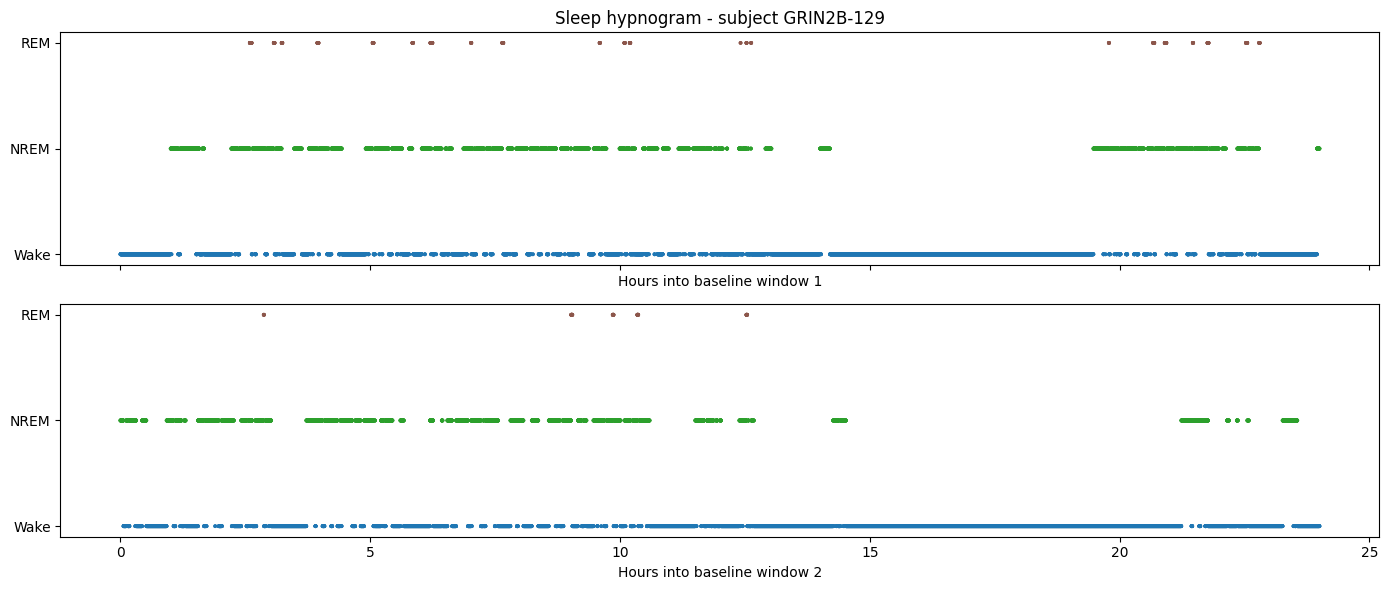

In [15]:
# Sleep hypnogram
t_mid = (sleep_df_bl1["start_time"] + sleep_df_bl1["stop_time"]) / 2
hours = (t_mid - bl1_start_time) / 3600  # hours into BL1 window

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
axes[0].scatter(
    hours,
    sleep_df_bl1["sleep_score"],
    s=3,
    c=sleep_df_bl1["sleep_score"],
    cmap="tab10",
    vmin=0,
    vmax=4,
)
axes[0].set_yticks([0, 1, 2])
axes[0].set_yticklabels(["Wake", "NREM", "REM"])
axes[0].set_xlabel("Hours into baseline window 1")
axes[1].scatter(
    hours,
    sleep_df_bl2["sleep_score"],
    s=3,
    c=sleep_df_bl2["sleep_score"],
    cmap="tab10",
    vmin=0,
    vmax=4,
)
axes[1].set_yticks([0, 1, 2])
axes[1].set_yticklabels(["Wake", "NREM", "REM"])
axes[1].set_xlabel("Hours into baseline window 2")
axes[0].set_title(f"Sleep hypnogram - subject {nwbfile.subject.subject_id}")
plt.tight_layout()
plt.show()

## 5. Sleep states by hour

Stacked bar chart of epoch counts per hour since lights-on (the start of each baseline window), as in the lab's
`States by Hour` plots.

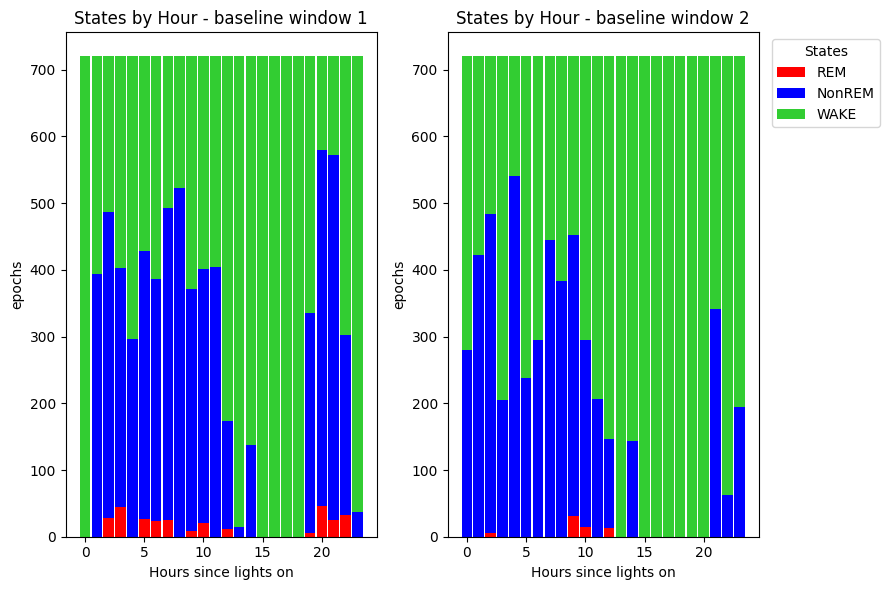

In [16]:
state_names = {0: "WAKE", 1: "NonREM", 2: "REM"}

# Bin each 5-s epoch into the hour since lights-on (the start of its baseline window)
hours_since_lights_on_bl1 = np.floor(
    (sleep_df_bl1["start_time"] - bl1_start_time) / 3600
).astype(int)

counts_by_hour_bl1 = (
    sleep_df_bl1["sleep_score"]
    .map(state_names)
    .groupby(hours_since_lights_on_bl1)
    .value_counts()
    .unstack(fill_value=0)
    .reindex(columns=["REM", "NonREM", "WAKE"], fill_value=0)
    .sort_index()
)

hours_since_lights_on_bl2 = np.floor(
    (sleep_df_bl2["start_time"] - bl2_start_time) / 3600
).astype(int)

counts_by_hour_bl2 = (
    sleep_df_bl2["sleep_score"]
    .map(state_names)
    .groupby(hours_since_lights_on_bl2)
    .value_counts()
    .unstack(fill_value=0)
    .reindex(columns=["REM", "NonREM", "WAKE"], fill_value=0)
    .sort_index()
)

fig, axes = plt.subplots(1,2, figsize=(9, 6))
bottom = np.zeros(len(counts_by_hour_bl1))
colors = {"WAKE": "limegreen", "NonREM": "blue", "REM": "red"}
for state in ["REM", "NonREM", "WAKE"]:
    axes[0].bar(
        counts_by_hour_bl1.index,
        counts_by_hour_bl1[state],
        bottom=bottom,
        width=0.9,
        color=colors[state],
        label=state,
    )
    bottom += counts_by_hour_bl1[state].to_numpy()

axes[0].set_xlabel("Hours since lights on")
axes[0].set_ylabel("epochs")
axes[0].set_title("States by Hour - baseline window 1")

bottom = np.zeros(len(counts_by_hour_bl2))
colors = {"WAKE": "limegreen", "NonREM": "blue", "REM": "red"}
for state in ["REM", "NonREM", "WAKE"]:
    axes[1].bar(
        counts_by_hour_bl2.index,
        counts_by_hour_bl2[state],
        bottom=bottom,
        width=0.9,
        color=colors[state],
        label=state,
    )
    bottom += counts_by_hour_bl2[state].to_numpy()

axes[1].set_xlabel("Hours since lights on")
axes[1].set_ylabel("epochs")
axes[1].set_title("States by Hour - baseline window 2")
axes[1].legend(title="States", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 6. HED tags and ontology terms of the sleep states

Each sleep state label is annotated in the file, so that the states can be found by standard terms instead of the
lab's labels:

- a **meanings table** on the `sleep_state` column, `sleep_state_meanings`, with the meaning of each label and its
  [HED](https://www.hedtags.org/) (Hierarchical Event Descriptors) tags;
- the **HED schema versions** the tags follow, in `nwbfile.lab_meta_data["hed_schema"]` (ndx-hed): the HED standard
  schema and the SCORE library, whose tags have the `sc:` prefix;
- a **HERD reference** from each label to a term of the [Neuro Behavior Ontology](https://www.ebi.ac.uk/ols4/ontologies/nbo) (section 11).

In [17]:
sleep_states = behavior["sleep_states"]
meanings_df = sleep_states.meanings_tables["sleep_state_meanings"].to_dataframe()
print("HED schema versions:", nwbfile.lab_meta_data["hed_schema"].hed_schema_version)
meanings_df

HED schema versions: ["8.4.0", "sc:score_2.1.0"]


,value,meaning,HED
id,,,
0,Wake,Wakefulness.,Awake
1,NREM,Non-rapid eye movement (NREM) sleep.,Asleep
2,REM,Rapid eye movement (REM) sleep.,"Asleep, sc:Sleep-stage-REM"


The ontology term of each state is in the file's HERD. Each reference points to the `value` column of the meanings
table, so it can be joined on the label:

In [18]:
references = nwbfile.external_resources.to_dataframe()
state_terms = references[references["key"].isin(meanings_df["value"])][["key", "entity_id", "entity_uri"]]
meanings_df.merge(state_terms, left_on="value", right_on="key").drop(columns="key")

,value,meaning,HED,entity_id,entity_uri
0,Wake,Wakefulness.,Awake,NBO:0000066,http://purl.obolibrary.org/obo/NBO_0000066
1,NREM,Non-rapid eye movement (NREM) sleep.,Asleep,NBO:0000161,http://purl.obolibrary.org/obo/NBO_0000161
2,REM,Rapid eye movement (REM) sleep.,"Asleep, sc:Sleep-stage-REM",NBO:0000159,http://purl.obolibrary.org/obo/NBO_0000159


HED tags make the states searchable across datasets that label them differently. For example, the sleep epochs are
the epochs whose state has a HED tag `Asleep`, whatever its label; here NREM and REM:

In [19]:
asleep_labels = meanings_df.loc[meanings_df["HED"].str.contains("Asleep"), "value"].tolist()
asleep = sleep_df[sleep_df["sleep_state"].isin(asleep_labels)]
print(f"Asleep labels: {asleep_labels}")
for window, epochs in asleep.groupby("baseline_window"):
    print(f"{window}: {len(epochs) * 5 / 3600:.1f} h asleep")

Asleep labels: ['NREM', 'REM']
baseline_window_1: 9.4 h asleep
baseline_window_2: 7.1 h asleep


The tags can be checked against their schemas with ndx-hed's validator (it downloads the HED schemas on first use):

In [20]:
from ndx_hed.utils.hed_nwb_validator import HedNWBValidator

issues = HedNWBValidator(nwbfile.lab_meta_data["hed_schema"]).validate_file(nwbfile)
print(f"{len(issues)} HED validation issues")

0 HED validation issues


## 7. Per-sleep-state power spectra

628 frequency bins per baseline window (0→125.2 Hz, 0.2 Hz steps = Nyquist of 250.4 Hz),
stored in a single table, `processing/ecephys/sleep_state_power_spectra`. Columns
are named after the brain state: `Wake`, `NREM`, `REM`, `SWD`; a `baseline_window` column
identifies which baseline window each row belongs to.

In [21]:
ecephys = nwbfile.processing["ecephys"]
psd_df = ecephys["sleep_state_power_spectra"].to_dataframe()
psd_df_bl1 = psd_df[psd_df["baseline_window"] == "baseline_window_1"]
psd_df_bl2 = psd_df[psd_df["baseline_window"] == "baseline_window_2"]

In [22]:
print(f"PSD table: {psd_df_bl1.shape}")
psd_df_bl1[:]

PSD table: (627, 6)


,frequency_hz,Wake,NREM,REM,SWD,baseline_window
id,,,,,,
0,0.0,0.519809,0.539314,0.123515,0.634967,baseline_window_1
1,0.2,0.497687,0.535483,0.108808,0.614226,baseline_window_1
2,0.4,0.483442,0.558114,0.093001,0.598746,baseline_window_1
3,0.6,0.453522,0.574946,0.070813,0.554426,baseline_window_1
4,0.8,0.439977,0.590124,0.068346,0.537512,baseline_window_1
...,...,...,...,...,...,...
622,124.4,0.042762,0.004024,0.005191,0.070005,baseline_window_1
623,124.6,0.042678,0.004111,0.005180,0.070263,baseline_window_1
624,124.8,0.042597,0.004328,0.005418,0.070568,baseline_window_1


In [23]:
print(f"PSD table: {psd_df_bl2.shape}")
psd_df_bl2[:]

PSD table: (627, 6)


,frequency_hz,Wake,NREM,REM,SWD,baseline_window
id,,,,,,
627,0.0,0.864452,0.935737,0.533670,1.050656,baseline_window_2
628,0.2,0.875762,0.965950,0.550871,1.060105,baseline_window_2
629,0.4,0.907634,1.033543,0.585353,1.090748,baseline_window_2
630,0.6,1.020505,1.194127,0.702763,1.190375,baseline_window_2
631,0.8,1.070288,1.274803,0.764896,1.238579,baseline_window_2
...,...,...,...,...,...,...
1249,124.4,0.046641,0.006989,0.006511,0.096875,baseline_window_2
1250,124.6,0.046434,0.007045,0.006427,0.096319,baseline_window_2
1251,124.8,0.046176,0.007037,0.006313,0.095381,baseline_window_2


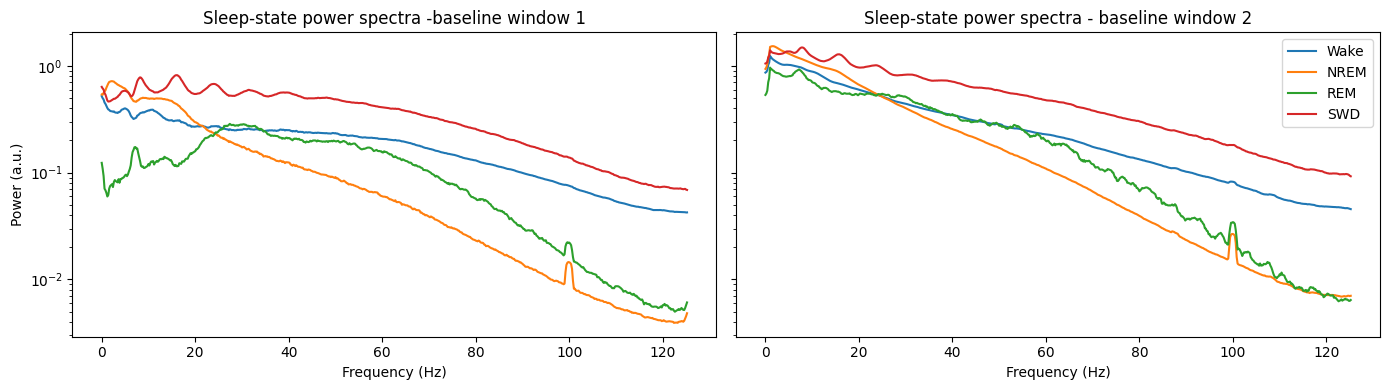

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
state_cols = ["Wake", "NREM", "REM", "SWD"]
for col in state_cols:
    if col in psd_df_bl1.columns:
        axes[0].semilogy(psd_df_bl1["frequency_hz"], psd_df_bl1[col], label=col)
# ax.set_xlim(0, 50)
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Power (a.u.)")
axes[0].set_title("Sleep-state power spectra -baseline window 1")
# axes[0].legend()
for col in state_cols:
    if col in psd_df_bl2.columns:
        axes[1].semilogy(psd_df_bl2["frequency_hz"], psd_df_bl2[col], label=col)
# ax.set_xlim(0, 50)
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_title("Sleep-state power spectra - baseline window 2")
axes[1].legend()

plt.tight_layout()
plt.show()

## 8. Seizure events

Stored as a `pynwbfile.epoch.TimeIntervals` table in
`processing/behavior/seizure_events`, spanning all baseline windows. The table has one
row per seizure event, with `start_time`, `stop_time`, `duration`, and `baseline_window`
columns - split on `baseline_window` to recover the BL1/BL2 subsets used below.

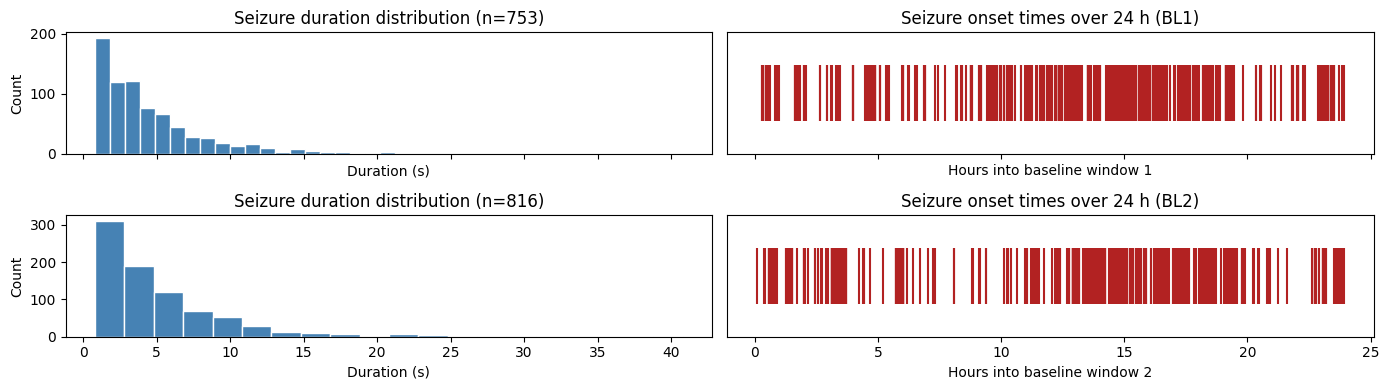

In [25]:
seizure_df = behavior["seizure_events"].to_dataframe()
seizure_df_bl1 = seizure_df[seizure_df["baseline_window"] == "baseline_window_1"]

start_times_bl1 = seizure_df_bl1["start_time"].to_numpy()
stop_times_bl1 = seizure_df_bl1["stop_time"].to_numpy()
durations_bl1 = seizure_df_bl1["duration"].to_numpy()

fig, axes = plt.subplots(2, 2, figsize=(14, 4), sharex="col")

# Duration histogram
axes[0][0].hist(durations_bl1, bins=20, color="steelblue", edgecolor="white")
axes[0][0].set_xlabel("Duration (s)")
axes[0][0].set_ylabel("Count")
axes[0][0].set_title(f"Seizure duration distribution (n={len(durations_bl1)})")

# Event timeline relative to BL1 window start
rel_start_bl1 = (start_times_bl1 - bl1_start_time) / 3600
axes[0][1].eventplot(rel_start_bl1, lineoffsets=0, linelengths=0.5, color="firebrick")
axes[0][1].set_xlabel("Hours into baseline window 1")
axes[0][1].set_yticks([])
axes[0][1].set_title("Seizure onset times over 24 h (BL1)")

seizure_df_bl2 = seizure_df[seizure_df["baseline_window"] == "baseline_window_2"]

start_times_bl2 = seizure_df_bl2["start_time"].to_numpy()
stop_times_bl2 = seizure_df_bl2["stop_time"].to_numpy()
durations_bl2 = seizure_df_bl2["duration"].to_numpy()

# Duration histogram
axes[1][0].hist(durations_bl2, bins=20, color="steelblue", edgecolor="white")
axes[1][0].set_xlabel("Duration (s)")
axes[1][0].set_ylabel("Count")
axes[1][0].set_title(f"Seizure duration distribution (n={len(durations_bl2)})")

# Event timeline relative to BL1 window start
rel_start_bl2 = (start_times_bl2 - bl2_start_time) / 3600
axes[1][1].eventplot(rel_start_bl2, lineoffsets=0, linelengths=0.5, color="firebrick")
axes[1][1].set_xlabel("Hours into baseline window 2")
axes[1][1].set_yticks([])
axes[1][1].set_title("Seizure onset times over 24 h (BL2)")

plt.tight_layout()
plt.show()

In [26]:
seizure_df[:]

,start_time,stop_time,duration,baseline_window
id,,,,
0,73350.3,73353.5,3.2,baseline_window_1
1,73356.7,73363.9,7.2,baseline_window_1
2,73381.3,73386.1,4.8,baseline_window_1
3,73389.1,73394.7,5.6,baseline_window_1
4,73404.1,73406.1,2.0,baseline_window_1
...,...,...,...,...
1564,244432.5,244435.7,3.2,baseline_window_2
1565,244439.7,244440.5,0.8,baseline_window_2
1566,244446.5,244449.7,3.2,baseline_window_2


## 9. EEG/EMG around a seizure event

Pick a seizure by index (`seizure_idx`) from the `seizure_events` table read in Section 7,
and automatically extract +/- `pad_s` seconds of raw EEG/EMG around it for plotting.

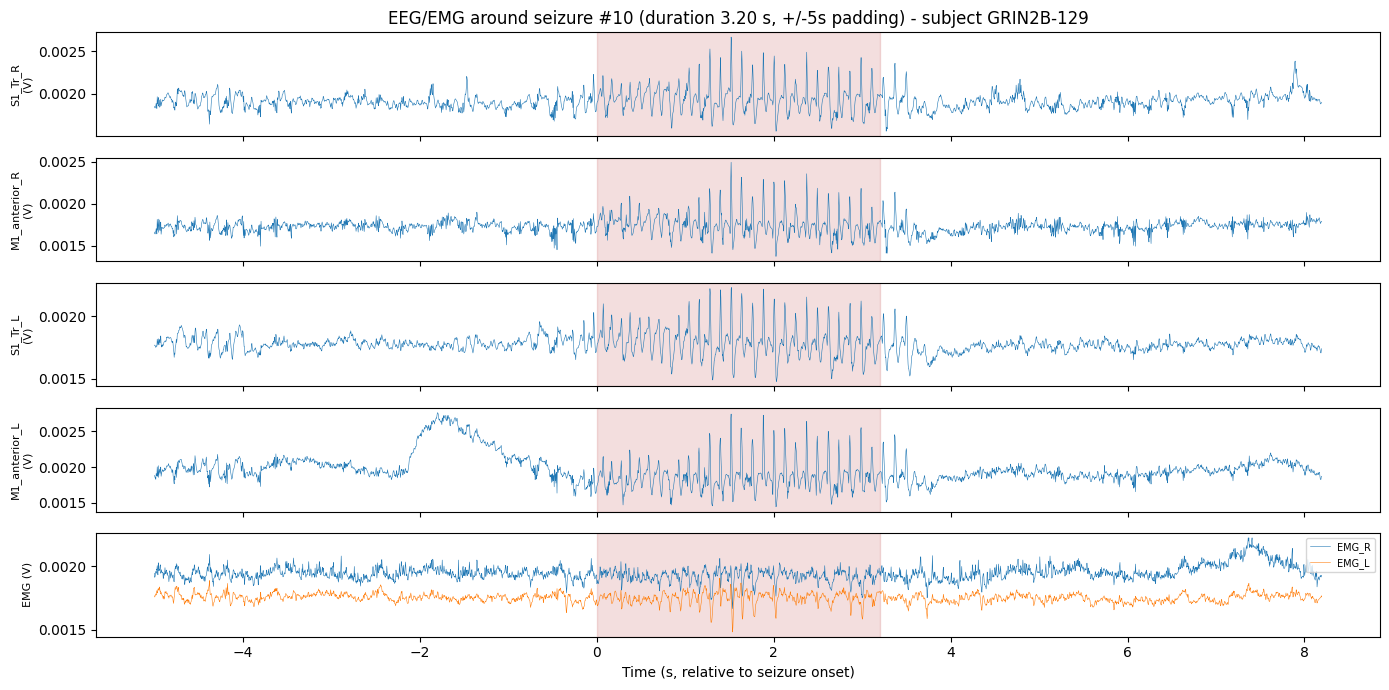

In [27]:
# ── Seizure selection ───────────────────────────────────────────────────────
seizure_idx = 10  # 10th seizure event (0-indexed)
pad_s = 5    # seconds of padding before/after the seizure to include
# ─────────────────────────────────────────────────────────────────────────────

seizure_onset_s = seizure_df["start_time"][seizure_idx]
seizure_offset_s = seizure_df["stop_time"][seizure_idx]

fs = eeg_es.rate

window_start_s = seizure_onset_s - pad_s
window_end_s = seizure_offset_s + pad_s

i_start = int(window_start_s * fs)
i_end = int(window_end_s * fs)
t = np.arange(i_start, i_end) / fs - (seizure_onset_s)  # t=0 at seizure onset

eeg_slice = eeg_es.data[i_start:i_end, :] * eeg_es.conversion + eeg_es.offset  # volts, lazy HDF5 read
emg_slice = emg_es.data[i_start:i_end, :] * emg_es.conversion + emg_es.offset  # volts, lazy HDF5 read

eeg_idx = {"S1_Tr_R": 0, "M1_anterior_R": 3, "S1_Tr_L": 13, "M1_anterior_L": 10}
emg_idx = {"EMG_R": 0, "EMG_L": 1}

fig, axes = plt.subplots(len(eeg_idx) + 1, 1, figsize=(14, 7), sharex=True)

for ax, (label, idx) in zip(axes[:-1], eeg_idx.items()):
    ax.plot(t, eeg_slice[:, idx], lw=0.4)
    ax.set_ylabel(f"{label}\n(V)", fontsize=8)

ax_emg = axes[-1]
for label, idx in emg_idx.items():
    ax_emg.plot(t, emg_slice[:, idx], lw=0.4, label=label)
ax_emg.set_ylabel("EMG (V)", fontsize=8)
ax_emg.legend(fontsize=7, loc="upper right")
ax_emg.set_xlabel("Time (s, relative to seizure onset)")

seizure_duration_s = seizure_offset_s - seizure_onset_s
for ax in axes:
    ax.axvspan(0, seizure_duration_s, color="firebrick", alpha=0.15)

axes[0].set_title(
    f"EEG/EMG around seizure #{seizure_idx} "
    f"(duration {seizure_duration_s:.2f} s, +/-{pad_s}s padding) - subject {nwbfile.subject.subject_id}"
)
plt.tight_layout()
plt.show()

## 10. Per-epoch SWD flags

`swd_epochs` is a `pynwb.epoch.TimeIntervals` table (one row per 5-s epoch) spanning all
baseline windows. Its boolean `is_swd` column is the flag the lab's sleep scorer uses to
label an epoch as SWD, and the `baseline_window` column identifies which baseline window
each row belongs to.

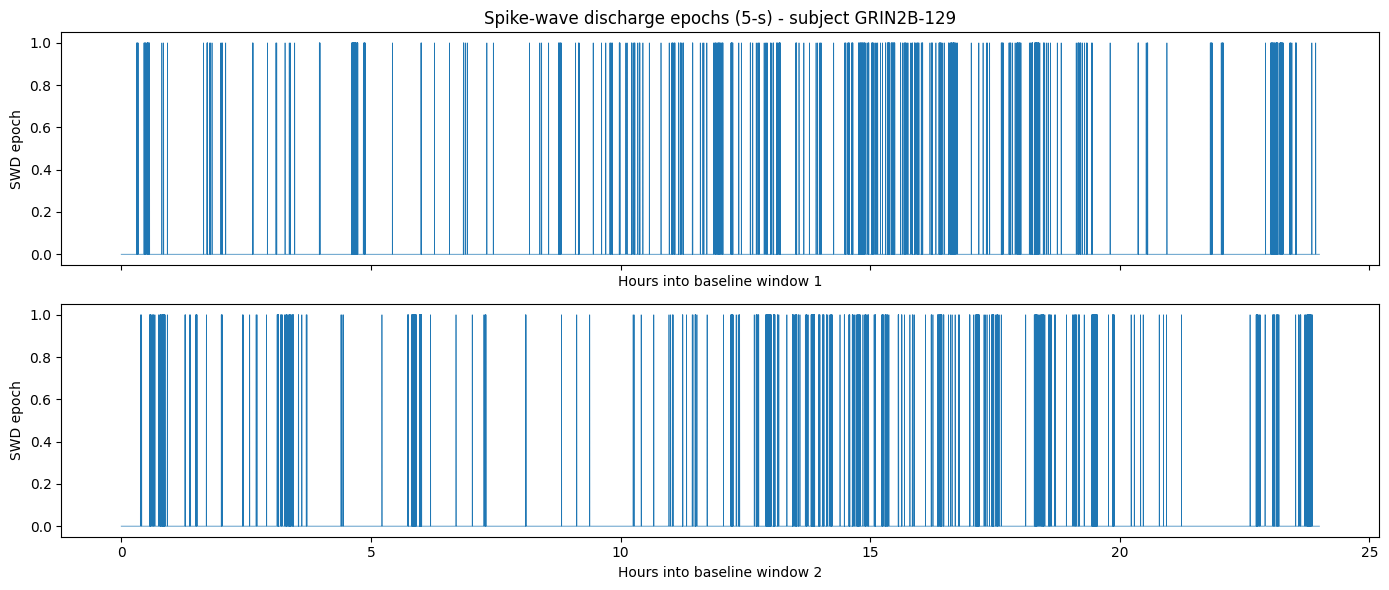

In [28]:
swd_df = behavior["swd_epochs"].to_dataframe()
swd_df_bl1 = swd_df[swd_df["baseline_window"] == "baseline_window_1"]
swd_df_bl2 = swd_df[swd_df["baseline_window"] == "baseline_window_2"]

hours_swd_bl1 = (swd_df_bl1["start_time"] - bl1_start_time) / 3600
hours_swd_bl2 = (swd_df_bl2["start_time"] - bl2_start_time) / 3600

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
axes[0].plot(hours_swd_bl1, swd_df_bl1["is_swd"].astype(int), lw=0.5)
axes[0].set_xlabel("Hours into baseline window 1")
axes[0].set_ylabel("SWD epoch")
axes[0].set_title(
    f"Spike-wave discharge epochs (5-s) - subject {nwbfile.subject.subject_id}"
)

axes[1].plot(hours_swd_bl2, swd_df_bl2["is_swd"].astype(int), lw=0.5)
axes[1].set_xlabel("Hours into baseline window 2")
axes[1].set_ylabel("SWD epoch")

plt.tight_layout()
plt.show()

## 11. External ontology resources (HERD)

NWB files can carry machine-readable links from metadata values to entities in external
ontologies via HDMF's **HERD** (HDMF External Resources Data), stored in-file under
`/general/external_resources`. Instead of a bare free-text string like `"Rattus norvegicus"`
or `"primary motor cortex, anterior (M1-Ant)"`, a HERD reference resolves that value to an unambiguous, resolvable term in a
controlled vocabulary - which is what lets archives like DANDI and other downstream tools
look up "what species / brain region is this, exactly" without guessing.

The conversion writes these references from the terms listed in its metadata
(`metadata/general_metadata.yaml` in the conversion repository); no term is inferred. In this dataset:

- **Subject species** (`Rattus norvegicus`) → [**NCBI Taxonomy**](https://bioregistry.io/registry/ncbitaxon)
  (`NCBITaxon`), the standard taxonomic identifier system used across biomedical databases.
- **Subject strain** (`Long-Evans`) → [**RRID**](https://bioregistry.io/registry/rrid) of Crl:LE
  (Charles River), the background strain the Grin2b line was made in.
- **Electrode / electrode-group `location`** (e.g. `primary motor cortex, anterior (M1-Ant)`, `cerebral cortex`,
  `trapezius muscle`) → [**UBERON**](https://bioregistry.io/registry/uberon), a cross-species anatomy ontology.
  UBERON has no rat-specific subdivisions of these cortical areas, so each one is mapped to its general area.
- **Experimenters** → [**ORCID**](https://bioregistry.io/registry/orcid) iDs, and the **institution** →
  [**ROR**](https://bioregistry.io/registry/ror).
- **Sleep states** (`Wake`, `NREM`, `REM`, the values of the `sleep_state_meanings` table) →
  [**NBO**](https://bioregistry.io/registry/nbo), the Neuro Behavior Ontology (section 6).

`nwbfile.external_resources` is a `HERD` object; calling `.to_dataframe()` flattens it into
one row per `(object, key, entity)` reference.

In [29]:
from IPython.display import HTML

herd = nwbfile.external_resources

if herd is None:
    print("This NWB file has no external resources (ontology annotations).")
else:
    resources_df = herd.to_dataframe()[
        ["object_type", "relative_path", "field", "key", "entity_id", "entity_uri"]
    ].reset_index(drop=True)

    # Render entity_uri as a clickable link so the ontology term can be opened directly
    display_df = resources_df.copy()
    display_df["entity_uri"] = display_df["entity_uri"].apply(
        lambda uri: f'<a href="{uri}" target="_blank">{uri}</a>'
    )
    display(HTML(display_df.to_html(escape=False, index=False)))

object_type,relative_path,field,key,entity_id,entity_uri
VectorData,,,Wake,NBO:0000066,http://purl.obolibrary.org/obo/NBO_0000066
VectorData,,,NREM,NBO:0000161,http://purl.obolibrary.org/obo/NBO_0000161
VectorData,,,REM,NBO:0000159,http://purl.obolibrary.org/obo/NBO_0000159
Subject,species,,Rattus norvegicus,NCBITaxon:10116,http://purl.obolibrary.org/obo/NCBITaxon_10116
Subject,strain,,Long-Evans,RRID:RGD_2308852,https://scicrunch.org/resolver/RRID:RGD_2308852
VectorData,,,"primary somatosensory cortex, trunk region (S1-Tr)",UBERON:0008933,http://purl.obolibrary.org/obo/UBERON_0008933
VectorData,,,"secondary motor cortex, frontal association area (M2-FrA)",UBERON:0016634,http://purl.obolibrary.org/obo/UBERON_0016634
VectorData,,,"secondary motor cortex, anterior (M2-Ant)",UBERON:0016634,http://purl.obolibrary.org/obo/UBERON_0016634
VectorData,,,"primary motor cortex, anterior (M1-Ant)",UBERON:0001384,http://purl.obolibrary.org/obo/UBERON_0001384
VectorData,,,"secondary visual cortex, mediolateral area (V2-ML)",UBERON:0022232,http://purl.obolibrary.org/obo/UBERON_0022232


### Referenced ontologies

Each `entity_id` is a CURIE (`PREFIX:local_id`), e.g. `NCBITaxon:10116` or `UBERON:0008933`.
The prefix identifies which ontology the term comes from. The cell below inspects the
prefixes actually present in this file and prints a clickable link to each ontology's
registry page (via [Bioregistry](https://bioregistry.io/), a registry of ontology
namespaces), along with a short description.

In [30]:
# Short descriptions of the ontologies whose prefixes may appear in entity_id
ONTOLOGY_INFO = {
    "NCBITaxon": ("NCBI Taxonomy", "Taxonomic identifiers (species) used across biomedical databases."),
    "UBERON": ("Uberon", "Cross-species anatomy ontology covering organs and gross anatomical structures."),
    "MBA": ("Allen Mouse Brain Atlas", "Structure ontology for the mouse brain."),
    "HBA": ("Allen Human Brain Atlas", "Structure ontology for the human brain."),
    "RRID": ("Research Resource Identifiers", "Identifiers for research resources, e.g. animal strains and antibodies."),
    "NBO": ("Neuro Behavior Ontology", "Ontology of behavioral processes and phenotypes, including sleep and wake states."),
    "orcid": ("ORCID", "Persistent identifiers of researchers."),
    "ror": ("Research Organization Registry", "Persistent identifiers of research organizations."),
}

if herd is not None and not resources_df.empty:
    prefixes = sorted({entity_id.split(":")[0] for entity_id in resources_df["entity_id"]})

    rows = []
    for prefix in prefixes:
        name, description = ONTOLOGY_INFO.get(prefix, (prefix, ""))
        url = f"https://bioregistry.io/registry/{prefix.lower()}"
        rows.append(
            f'<li><a href="{url}" target="_blank"><b>{name}</b></a> '
            f'(<code>{prefix}</code>) - {description}</li>'
        )

    display(HTML("<ul>" + "".join(rows) + "</ul>"))

In [31]:
# Close the file when done
io.close()